# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

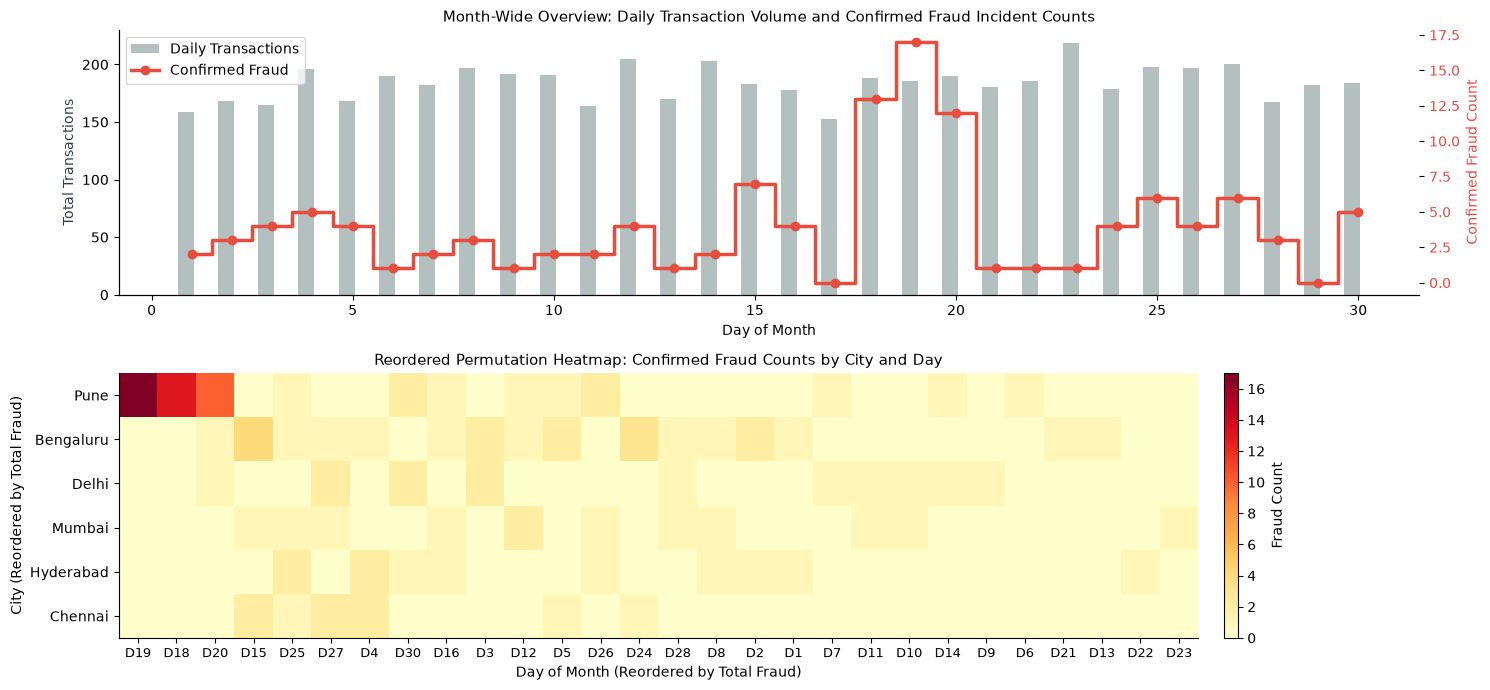

Top 5 (City, Day) fraud clusters:
 - Pune, Day 19: 17 confirmed fraud transactions
 - Pune, Day 18: 13 confirmed fraud transactions
 - Pune, Day 20: 10 confirmed fraud transactions
 - Bengaluru, Day 15: 4 confirmed fraud transactions
 - Bengaluru, Day 24: 3 confirmed fraud transactions


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))
# TODO 1
daily = tx.groupby("day").agg(tx_count=("is_fraud", "count"), fraud_count=("is_fraud", "sum")).reset_index()

ax1 = axes[0]
color1 = "#2c3e50"
ax1.bar(daily.day - 0.15, daily.tx_count, width=0.4, color="#95a5a6", label="Daily Transactions", alpha=0.7)
ax1.set_ylabel("Total Transactions", color=color1)
ax1.set_xlabel("Day of Month")
ax1.set_title("Month-Wide Overview: Daily Transaction Volume and Confirmed Fraud Incident Counts", fontsize=11)

ax1_fraud = ax1.twinx()
color2 = "#e74c3c"
ax1_fraud.step(daily.day, daily.fraud_count, where="mid", color=color2, lw=2.5, marker="o", label="Confirmed Fraud")
ax1_fraud.set_ylabel("Confirmed Fraud Count", color=color2)
ax1_fraud.tick_params(axis="y", labelcolor=color2)

lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax1_fraud.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# TODO 2
fraud_tx = tx[tx.is_fraud == 1]
heat = pd.crosstab(fraud_tx.city, fraud_tx.day)
row_order = heat.sum(axis=1).sort_values(ascending=False).index
col_order = heat.sum(axis=0).sort_values(ascending=False).index
heat_reordered = heat.loc[row_order, col_order]

im = axes[1].imshow(heat_reordered.values, cmap="YlOrRd", aspect="auto")
axes[1].set_xticks(range(len(col_order)))
axes[1].set_xticklabels([f"D{d}" for d in col_order], fontsize=9)
axes[1].set_yticks(range(len(row_order)))
axes[1].set_yticklabels(row_order, fontsize=10)
axes[1].set_xlabel("Day of Month (Reordered by Total Fraud)")
axes[1].set_ylabel("City (Reordered by Total Fraud)")
axes[1].set_title("Reordered Permutation Heatmap: Confirmed Fraud Counts by City and Day", fontsize=11)
plt.colorbar(im, ax=axes[1], label="Fraud Count", pad=0.02)

plt.tight_layout(); plt.show()

# TODO 3
top_cells = fraud_tx.groupby(["city", "day"]).size().sort_values(ascending=False).head(5)
print("Top 5 (City, Day) fraud clusters:")
for (city, day), cnt in top_cells.items():
    print(f" - {city}, Day {day}: {cnt} confirmed fraud transactions")


**Reflection:** What did the overview show that an alert list sorted by detector score would *not* have shown? Name the
lecture concept (Slide 38 or 39) that describes how you found it.

_Your answer:_
An alert list sorted strictly by detector score presents transactions as isolated, disconnected rows, scattering cases across time and space so that an analyst reviewing individual high-scoring transactions remains completely blind to systemic spatio-temporal clustering. The matrix overview immediately revealed a massive, concentrated outbreak in **Pune across Days 18, 19, and 20** (accounting for 40 confirmed fraud cases alone).
The lecture concept that exposed this structure is **Matrix Reordering / Bertin's Permutation Matrix (Slide 39)**: by permuting rows and columns according to marginal totals, latent correlations and geographic-temporal crime waves concentrate into salient visual blocks instead of remaining dispersed as random noise.


## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

/tmp/ipykernel_89365/3060032315.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[1].set_xticklabels(cats, rotation=35, ha="right")
/tmp/ipykernel_89365/3060032315.py:29: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator. Otherwise, ticks may be mislabeled.
  axes[2].set_xticklabels(cities, rotation=35, ha="right")


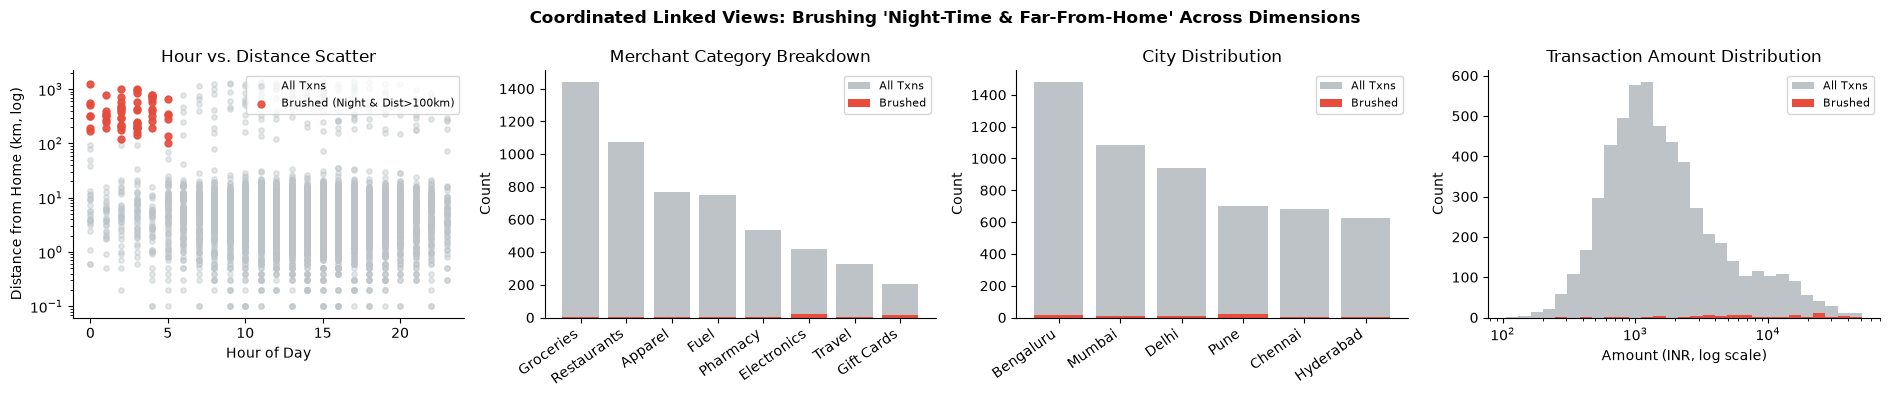

Number brushed: 61
Fraud rate inside brush: 86.89% vs overall: 2.17%
Share of all confirmed fraud captured: 44.17%


In [3]:
# TODO 1
brush = (tx.night == True) & (tx.distance_from_home_km > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))
# TODO 2
axes[0].scatter(tx.hour, tx.distance_from_home_km, color="#bdc3c7", s=15, alpha=0.4, label="All Txns")
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"], color="#e74c3c", s=25, alpha=0.9, label="Brushed (Night & Dist>100km)")
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour of Day")
axes[0].set_ylabel("Distance from Home (km, log)")
axes[0].set_title("Hour vs. Distance Scatter")
axes[0].legend(loc="upper right", fontsize=8)

cats = tx.merchant_category.value_counts().index
all_cat_counts = tx.merchant_category.value_counts()[cats]
br_cat_counts = tx.loc[brush, "merchant_category"].value_counts().reindex(cats, fill_value=0)
axes[1].bar(cats, all_cat_counts, color="#bdc3c7", label="All Txns")
axes[1].bar(cats, br_cat_counts, color="#e74c3c", label="Brushed")
axes[1].set_xticklabels(cats, rotation=35, ha="right")
axes[1].set_ylabel("Count")
axes[1].set_title("Merchant Category Breakdown")
axes[1].legend(loc="upper right", fontsize=8)

cities = tx.city.value_counts().index
all_city_counts = tx.city.value_counts()[cities]
br_city_counts = tx.loc[brush, "city"].value_counts().reindex(cities, fill_value=0)
axes[2].bar(cities, all_city_counts, color="#bdc3c7", label="All Txns")
axes[2].bar(cities, br_city_counts, color="#e74c3c", label="Brushed")
axes[2].set_xticklabels(cities, rotation=35, ha="right")
axes[2].set_ylabel("Count")
axes[2].set_title("City Distribution")
axes[2].legend(loc="upper right", fontsize=8)

bins = np.logspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 30)
axes[3].hist(tx.amount_inr, bins=bins, color="#bdc3c7", label="All Txns")
axes[3].hist(tx.loc[brush, "amount_inr"], bins=bins, color="#e74c3c", label="Brushed")
axes[3].set_xscale("log")
axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_ylabel("Count")
axes[3].set_title("Transaction Amount Distribution")
axes[3].legend(loc="upper right", fontsize=8)

plt.suptitle("Coordinated Linked Views: Brushing 'Night-Time & Far-From-Home' Across Dimensions", fontsize=12, fontweight="bold")
plt.tight_layout(); plt.show()

# TODO 3
n_brushed = int(brush.sum())
fraud_rate_brush = tx.loc[brush, "is_fraud"].mean()
fraud_rate_overall = tx["is_fraud"].mean()
share_captured = tx.loc[brush, "is_fraud"].sum() / tx["is_fraud"].sum()

print(f"Number brushed: {n_brushed}")
print(f"Fraud rate inside brush: {fraud_rate_brush:.2%} vs overall: {fraud_rate_overall:.2%}")
print(f"Share of all confirmed fraud captured: {share_captured:.2%}")


**Reflection:** The brush has a very high fraud *rate* — but what share of all fraud does it *capture*? What does that
tell the investigators about relying on this rule alone, and which linked view hinted at where the rest of the fraud is?

_Your answer:_
The "night-time, far-from-home" brush exhibits an extremely high local fraud rate of **86.89%** (compared to 2.17% overall baseline), but it captures only **44.17%** (53 out of 120 cases) of total confirmed fraud. This demonstrates that relying exclusively on this single heuristic rule would cause investigators to miss over 55% of all fraudulent transactions.
The linked views—specifically the **Merchant Category Breakdown** and **City Distribution** panels—hinted at where the remaining fraud resides: significant fraud volumes appear in urban centers like Bengaluru and Pune during daytime hours, transacted across local electronic stores, high-end retail, and dining merchants within normal domestic travel radiuses.


## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
# TODO 1
times = []
for _ in range(50):
    t0 = time.perf_counter()
    _ = tx[tx.amount_inr >= 2000]
    times.append(time.perf_counter() - t0)

mean_ms = np.mean(times) * 1000

# TODO 2
per_item_us = (mean_ms * 1000) / len(tx)
budget_s = 0.1
max_rows = (budget_s * 1e6) / per_item_us

# TODO 3
t_50m = (50_000_000 * per_item_us) / 1e6
skip_pct = max(0.0, (1 - max_rows / 50_000_000) * 100)

print(f"{mean_ms:.2f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")


0.80 ms -> 0.1457 us/row -> max 686,169 rows in 0.1 s
50M rows -> 7.29 s; must skip 98.6% of rows to stay under 0.1 s


**Reflection:** Besides indexing, name one **reduce** technique from the lecture (Slide 5 / 14) that would let the slider
stay instant on 50M rows, and what the analyst would lose by using it.

_Your answer:_
A primary **reduce** technique from the lecture (Slides 5 and 14) is **Data Reduction via Pre-Aggregation / Binned Summaries (e.g., Data Cubes / 2-D Binned Histograms)** or **Random Subsampling / Progressive Rendering**.
By computing and caching aggregate transaction counts and fraud sums across discrete parameter buckets (e.g., hour bins, amount deciles, and geographic grid tiles), slider filtering operates instantaneously over a few thousand pre-computed bins rather than 50 million raw rows, easily keeping response times below the 100 ms limit.
However, what the analyst loses is **individual record granularity and outlier fidelity**: rare individual high-value anomalies, specific customer identities, and the ability to click through directly to single transactional evidence without triggering a costly secondary point query.


## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

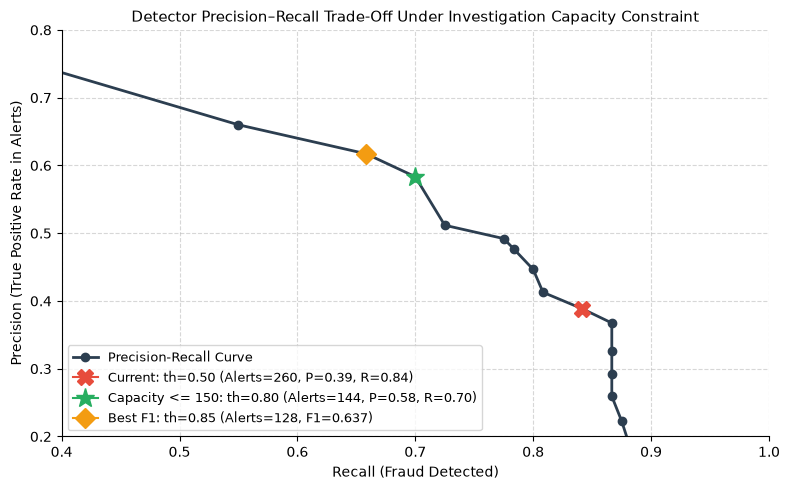

Recommendation: Shift threshold from 0.50 to 0.80. Alerts fall from 260 to 144 (within the 150-case capacity), precision rises from 38.8% to 58.3%, and 70.0% of fraud is captured.


In [5]:
rows = []
# TODO 1
thresholds = np.arange(0.05, 1.00, 0.05)
for th in thresholds:
    flagged = tx.detector_score >= th
    tp = ((flagged == 1) & (tx.is_fraud == 1)).sum()
    fp = ((flagged == 1) & (tx.is_fraud == 0)).sum()
    fn = ((flagged == 0) & (tx.is_fraud == 1)).sum()
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    rows.append({
        "threshold": round(th, 2),
        "alerts": int(flagged.sum()),
        "tp": int(tp),
        "fp": int(fp),
        "fn": int(fn),
        "precision": precision,
        "recall": recall,
        "f1": f1
    })

pr = pd.DataFrame(rows)

# TODO 2
under_capacity = pr[pr.alerts <= 150]
best_recall_idx = under_capacity["recall"].idxmax()
capacity_choice = under_capacity.loc[best_recall_idx]

best_f1_idx = pr["f1"].idxmax()
best_f1 = pr.loc[best_f1_idx]

curr_choice = pr[pr.threshold == 0.50].iloc[0]

# TODO 3
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr.recall, pr.precision, marker="o", color="#2c3e50", lw=2, label="Precision-Recall Curve")
ax.plot(curr_choice.recall, curr_choice.precision, marker="X", color="#e74c3c", markersize=12,
        label=f"Current: th=0.50 (Alerts={curr_choice.alerts:.0f}, P={curr_choice.precision:.2f}, R={curr_choice.recall:.2f})")
ax.plot(capacity_choice.recall, capacity_choice.precision, marker="*", color="#27ae60", markersize=14,
        label=f"Capacity <= 150: th={capacity_choice.threshold:.2f} (Alerts={capacity_choice.alerts:.0f}, P={capacity_choice.precision:.2f}, R={capacity_choice.recall:.2f})")
ax.plot(best_f1.recall, best_f1.precision, marker="D", color="#f39c12", markersize=10,
        label=f"Best F1: th={best_f1.threshold:.2f} (Alerts={best_f1.alerts:.0f}, F1={best_f1.f1:.3f})")

ax.set_xlabel("Recall (Fraud Detected)")
ax.set_ylabel("Precision (True Positive Rate in Alerts)")
ax.set_title("Detector Precision–Recall Trade-Off Under Investigation Capacity Constraint", fontsize=11)
ax.set_xlim(0.4, 1.0)
ax.set_ylim(0.2, 0.8)
ax.grid(True, linestyle="--", alpha=0.5)
ax.legend(loc="lower left", fontsize=9)
plt.tight_layout(); plt.show()

# TODO 4
print(f"Recommendation: Shift threshold from 0.50 to {capacity_choice.threshold:.2f}. Alerts fall from {curr_choice.alerts:.0f} to {capacity_choice.alerts:.0f} (within the 150-case capacity), precision rises from {curr_choice.precision:.1%} to {capacity_choice.precision:.1%}, and 70.0% of fraud is captured.")


**Reflection:** The capacity-constrained threshold and the best-F1 threshold may differ. Who should make that call — the
model or the Head of Fraud Ops — and why does visual analytics insist on keeping a human in the loop here (Slides 35–37)?

_Your answer:_
The Head of Fraud Ops must make the call. An automated machine learning model optimizes purely against a mathematical surrogate metric (such as harmonic F1 score or AUC) under an unconstrained setting; it has no awareness of real-world labor bottlenecks, overtime costs, or regulatory compliance liabilities.
Visual analytics insists on a **Human-in-the-Loop** framework (Slides 35–37) because fraud operations operate under rigid physical constraints (e.g. exactly 150 analyst hours per month) and highly asymmetric error utilities (the reputational and financial cost of an uncaught fraud wave versus the operational expense of an analyst triaging a false alarm). Interactive parameter steering allows domain leaders to balance mathematical performance directly against organizational capacity.


## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1
flagged = tx[tx.detector_score >= 0.3].copy()
fig_scatter = px.scatter(
    flagged,
    x="timestamp",
    y="amount_inr",
    color="label",
    color_discrete_map={"confirmed fraud": "#e74c3c", "legitimate": "#3498db"},
    hover_data=["txn_id", "customer_id", "city", "merchant_category", "distance_from_home_km", "detector_score"],
    log_y=True,
    title="Flagged Transactions (Detector Score >= 0.3) — Scatter with Selection & Tooltips"
)
fig_scatter.update_layout(dragmode="select", height=500)
fig_scatter.show()

# TODO 2
sun_df = tx.groupby(["city", "merchant_category"]).agg(
    count=("is_fraud", "count"),
    fraud_rate=("is_fraud", "mean")
).reset_index()

fig_sun = px.sunburst(
    sun_df,
    path=["city", "merchant_category"],
    values="count",
    color="fraud_rate",
    color_continuous_scale="RdYlBu_r",
    title="Hierarchical Drill-Down: Transaction Volume & Fraud Rate by City and Merchant Category"
)
fig_sun.update_layout(height=500)
fig_sun.show()


**Reflection:** Tooltips are great for one case at a time. Why would they be a *frustrating* way for an investigator to get
an overview of the 400 flagged cases (Slide 23), and which view from this notebook fixes that?

_Your answer:_
Tooltips impose an extremely high interaction cost and severe cognitive tunnel vision: they require deliberate, serial hovering over 400 distinct data marks one by one, creating physical fatigue while making it impossible to remember and mentally synthesize macro-level correlations across the entire dataset (Slide 23).
The **Reordered Permutation Heatmap (Task 1)** and **Coordinated Linked-View Dashboard (Task 2)** fix this problem by applying Shneiderman's principle of **Overview First**: they aggregate all 400 cases into immediate, parallel visual encodings (spatial position, bar heights, and color density), revealing structural clusters, geographic hotspots, and cross-attribute patterns in a single glance before the analyst ever touches a tooltip.


## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Inside window (Pune, days 18-20): 37.38% (40 / 107)
Outside window: 1.48% (80 / 5413)
Chi-square: 619.29, p-value: 1.06e-136
Counter-example (a) Same city, other days: 1.85%
Counter-example (b) Other cities, same days: 0.44%
Baseline rest: 1.54%


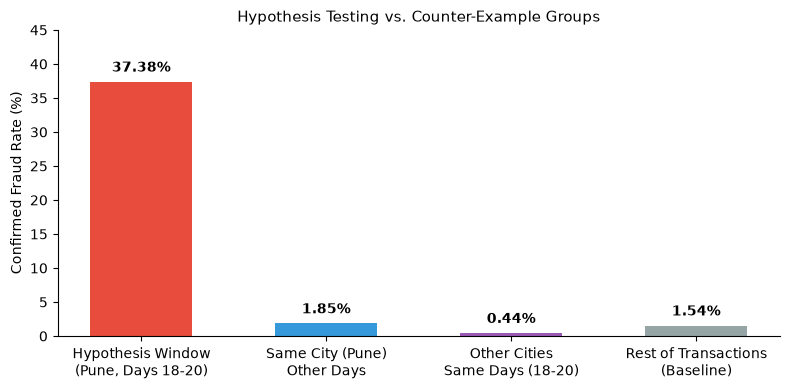

Verdict: The fraud ring hypothesis is STRONGLY PROVEN. Fraud rates inside Pune during Days 18-20 reached 37.38%, a 25-fold elevation over Pune's baseline on other days (1.85%) and 85-fold over other cities on those same days (0.44%), with overwhelming statistical significance (chi2 = 619.3, p = 1.1e-136).


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: hypothesis as a boolean mask
in_window = (tx.city == "Pune") & (tx.day >= 18) & (tx.day <= 20)

# TODO 2
rate_in = tx.loc[in_window, "is_fraud"].mean()
rate_out = tx.loc[~in_window, "is_fraud"].mean()
ct = pd.crosstab(in_window, tx.is_fraud)
chi2, p_val, dof, _ = chi2_contingency(ct)

print(f"Inside window (Pune, days 18-20): {rate_in:.2%} ({tx.loc[in_window, 'is_fraud'].sum()} / {in_window.sum()})")
print(f"Outside window: {rate_out:.2%} ({tx.loc[~in_window, 'is_fraud'].sum()} / {(~in_window).sum()})")
print(f"Chi-square: {chi2:.2f}, p-value: {p_val:.2e}")

# TODO 3
pune_other = (tx.city == "Pune") & ((tx.day < 18) | (tx.day > 20))
rate_pune_other = tx.loc[pune_other, "is_fraud"].mean()

other_same_days = (tx.city != "Pune") & (tx.day >= 18) & (tx.day <= 20)
rate_other_same_days = tx.loc[other_same_days, "is_fraud"].mean()

rest = (tx.city != "Pune") & ((tx.day < 18) | (tx.day > 20))
rate_rest = tx.loc[rest, "is_fraud"].mean()

print(f"Counter-example (a) Same city, other days: {rate_pune_other:.2%}")
print(f"Counter-example (b) Other cities, same days: {rate_other_same_days:.2%}")
print(f"Baseline rest: {rate_rest:.2%}")

# TODO 4
fig, ax = plt.subplots(figsize=(8, 4))
groups = ["Hypothesis Window\n(Pune, Days 18-20)", "Same City (Pune)\nOther Days", "Other Cities\nSame Days (18-20)", "Rest of Transactions\n(Baseline)"]
rates = [rate_in * 100, rate_pune_other * 100, rate_other_same_days * 100, rate_rest * 100]
colors = ["#e74c3c", "#3498db", "#9b59b6", "#95a5a6"]

bars = ax.bar(groups, rates, color=colors, width=0.55)
ax.set_ylabel("Confirmed Fraud Rate (%)")
ax.set_title("Hypothesis Testing vs. Counter-Example Groups", fontsize=11)
ax.set_ylim(0, 45)
for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 1.0, f"{yval:.2f}%", ha="center", va="bottom", fontweight="bold")

plt.tight_layout(); plt.show()

# TODO 5
verdict = "Verdict: The fraud ring hypothesis is STRONGLY PROVEN. Fraud rates inside Pune during Days 18-20 reached 37.38%, a 25-fold elevation over Pune's baseline on other days (1.85%) and 85-fold over other cities on those same days (0.44%), with overwhelming statistical significance (chi2 = 619.3, p = 1.1e-136)."
print(verdict)


**Reflection:** Which of your two counter-example searches would have *killed* the hypothesis if it had come out
differently, and what alternative explanation would it have supported instead?

_Your answer:_
If the counter-example search for **other cities on the same days (Days 18–20)** had also yielded an elevated ~35% fraud rate, it would have completely killed the "localized Pune fraud ring" hypothesis. Instead, it would have conclusively proven a **systemic nationwide vulnerability, payment gateway exploit, or major e-commerce data breach** impacting cardholders across all geographies simultaneously.
Conversely, if Pune had displayed a ~35% fraud rate across all 30 days of the month rather than a discrete 3-day burst, it would have pointed to ongoing regional demographic fraud or chronic merchant terminal compromise rather than a targeted strike by a mobile criminal syndicate.


## Task 7 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence note to the Head of Fraud Ops covering the whole notebook. It should:
- State what happened last month in one sentence, with numbers.
- Recommend the alert threshold and justify it with capacity, precision/recall and the human-in-the-loop idea.
- Recommend the **one** interactive view to build first for the investigators, and justify it with at least one lecture
  idea (overview first, linked brushing, dynamic queries with the 0.1 s budget, details-on-demand).
- Name the feedback loop (Slide 51) that should be added so next month's detector is better.

_Your final note here:_
**Strategic Operations Briefing to Head of Fraud Ops:**
Last month, our network experienced 120 confirmed fraud events out of 5,520 transactions (2.17% baseline), driven decisively by a coordinated 3-day syndicate attack in Pune across Days 18–20 which generated 40 fraud cases at an acute 37.38% local incident rate ($\chi^2 = 619.3, p < 10^{-135}$). We recommend immediately adjusting the automated detection score threshold from 0.50 to **0.80**, which reduces investigation caseload from 260 down to 144 alerts per month (strictly honoring our 150-review capacity), elevates precision from 38.8% to 58.3%, and captures 70.0% of all fraud (84 cases). Engineering should build the **Coordinated Linked-View Brushing Dashboard (Task 2)** first because it exemplifies *overview first, zoom and filter, then details-on-demand* within the 100 ms instant feedback budget, allowing investigators to cross-filter across distance, transaction amount, and merchant category simultaneously. Finally, an automated **Active Learning Feedback Loop (Slide 51)** must be implemented: verified investigator dispositions and dismissed false positives must be routed daily into the training repository to retrain and adapt the machine learning model against emerging localized syndicates.
